# Can a model write executable bytes directly?

A processor follows small instructions: fetch a number, add another number, jump to a different instruction, or return an answer. Software developers usually describe the work in a programming language. A compiler translates that description into the instruction bytes the processor can run. Testing whether a language model can supply those bytes itself asks how much of that translation it can carry out without the usual software tools.

That question matters in two different situations. Someone building a tiny calculation may want to know whether a model understands the processor's instructions well enough to produce a working function. Someone asking for a program they can launch needs more: an operating system must recognise the file and know where its instructions begin. A useful result must identify which of these capabilities was demonstrated.

Consider this **illustrative example**, separate from the measured tests. A calculation takes two whole numbers, multiplies the first by 37 and the second by 11, and adds 23. With inputs 2 and 3, the answer is 74 + 33 + 23 = 130. A programmer could write that calculation in a familiar language and ask a compiler to translate it.

The complication is that a processor stores a fixed amount of information in each number. This study uses unsigned 64-bit numbers, which run from zero to 18,446,744,073,709,551,615. Adding one to the largest value wraps back to zero. That wrap is part of the requested calculation, so a program that merely works for 2 and 3 has not yet shown that it handles the whole interface correctly.

One approach lets the model describe the processor instructions using names such as “multiply” and “return.” An assembler turns those instruction names into bytes and calculates their encodings. This removes a clerical burden while leaving the algorithm to the model. Assembly is the name for that readable instruction language.

A second approach asks the model for the bytes themselves. We write them to memory unchanged and check the answer when a processor emulator runs them. There is no assembler in that path. A third approach asks for an entire executable file, including the information Linux needs to load it and the instructions for reading inputs and writing the answer. ELF is the executable file format used for this test.

These are different amounts of work. A working function proves that generated instruction bytes can calculate an answer under a supplied calling convention. A working ELF file also proves that the model can put instructions into a file the Linux loader accepts. Neither result establishes that the model can produce a large application, make it portable, or improve on an optimising compiler.

The question is therefore narrow: can one current coding model produce correct raw functions and complete executable files for two small tasks, on its first attempt, without using generation tools? The assembly version supplies a control for the same calculations, and the saved usage answers a second practical question: how many tokens did those attempts actually take?

## Study summary

GPT-6.1 Sol produced all six requested programs correctly: two raw functions, two complete ELF files, and two assembly controls. Each program passed all 128 hidden input pairs. The complete executable files were 192 and 224 bytes and ran through the actual Linux loader in a local container, with every byte supplied by the model. No compiler, assembler, generated header or wrapper was added to either ELF response.

There were zero unreadable replies, zero execution failures and zero wrong answers. Correctness means the exact requested integer result on all hidden inputs, plus a successful return for functions or exactly eight output bytes and exit status zero for executables. The all-attempt and readable-only scores are both six of six. This is a ceiling: no task separates the formats, and these two familiar algorithms cannot rank methods or establish reliability on larger software.

The six calls used 43,327 input tokens and 4,903 output tokens. The CLI identifies 4,311 of those output tokens as reasoning and 592 as final artifacts. Their standard API equivalent is US$0.124254, including reported input-cache reads. This is a conversion from measured tokens, not an observed subscription invoice. The evidence supports a small existence claim: direct executable generation already works for these cases. It does not test the stronger claim that direct binaries will replace normal software development or outperform compilers.

## Contents

- [1. Setup and scope](#1-setup-and-scope)
- [2. Data and exact answers](#2-data-and-exact-answers)
- [3. Three ways to supply a program](#3-three-ways-to-supply-a-program)
- [4. From a response to a checked answer](#4-from-a-response-to-a-checked-answer)
- [5. Correctness and executable files](#5-correctness-and-executable-files)
- [6. Token usage and cost](#6-token-usage-and-cost)
- [7. Error analysis and boundary cases](#7-error-analysis-and-boundary-cases)
- [8. What this result supports](#8-what-this-result-supports)
- [9. Reproduction and saved evidence](#9-reproduction-and-saved-evidence)
- [10. Future work and further reading](#10-future-work-and-further-reading)

```mermaid
flowchart TD
    spec["2 task specifications<br/>affine arithmetic and GCD"] --> prompts["6 frozen requests<br/>2 tasks x 3 formats"]
    inputs["128 hidden input pairs per task<br/>256 labelled task cases"] --> gold["Exact Python answers<br/>256 expected integers"]
    prompts --> calls["GPT-6.1 Sol via codex exec<br/>6 independent first attempts"]
    calls --> cache["6 immutable cached responses<br/>raw events and usage"]
    cache --> raw["2 raw hex responses<br/>decode bytes only"]
    cache --> elf["2 complete ELF hex responses<br/>decode bytes only"]
    cache --> asm["2 assembly responses<br/>Keystone encodes instructions"]
    raw --> emu["Unicorn CPU emulator<br/>4 functions x 128 inputs"]
    asm --> emu
    elf --> linux["Linux loader in Docker<br/>2 executables x 128 inputs"]
    emu --> score["768 exact comparisons<br/>plus format and execution checks"]
    linux --> score
    gold --> score
    score --> report["6 program scores<br/>token and cost tables, figures"]
```

One measured example is `affine-004`, with inputs 6 and 9. Its specification goes to the model, but its input values stay with the evaluator. The returned raw bytes execute with those numbers in the specified registers. The evaluator compares the resulting 344 with its independently computed 344. The same pair is also tested through the complete file's standard input and the assembled control, so those three observations concern the same calculation. The 768 comparisons are repeated tests of six programs, not 768 independently generated programs.

<a id="1-setup-and-scope"></a>

## 1. Setup and scope

This experiment tests one model in three output formats. Choosing one model keeps the initial collection small enough to measure usage before designing a broader study. It also means there is no evidence here about which provider or model is better at this task. High reasoning effort is fixed across all six requests; there is no effort sweep or instruction tuning.

| Model | Pinned identifier and revision visibility | Provider and call route | Published size and precision | Output settings | Why included |
|---|---|---|---|---|---|
| GPT-6.1 Sol | `gpt-6.1-sol`; CLI 0.160.1; an immutable dated weight snapshot is not exposed by this route | OpenAI, `codex exec`, fresh ephemeral session per request | Not published | High reasoning effort; explicit default service tier; supported default sampling; neutral base instruction; tools disabled and observed events audited | One current coding model for an initial existence and usage test |

The model identifier is fixed, but that is weaker than pinning an immutable weight revision. A future fresh run could receive different model weights under the same identifier. Saved responses preserve the actual evidence for this run. The official model page gives a knowledge cutoff of April 30, 2026; the evaluation inputs were generated on November 3, 2026. [Model documentation](https://developers.openai.com/api/docs/models/gpt-6.1-sol).

The simpler alternative would ask for a familiar source language and run its compiler. That would test source generation and the compiler together. Assembly is a closer control because the model already chooses processor instructions while the assembler handles encodings and label offsets. It is still a different workflow from a model writing all file bytes itself. This pilot measures whether each workflow can succeed, rather than claiming that the three require the same work.

Before collection, the request list, task rules, inputs, primary score and parsing policy were fixed in [the protocol](data/PROTOCOL.md). One first attempt occupies each slot. There is no feedback, correction conversation or selection of the best of several candidates. A fresh session does not see another artifact, the hidden cases, the expected answers or a test result. The following setup defines every helper inside the notebook and defaults to replay without model calls.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, math, os, random, re, shutil, struct, subprocess, tempfile, time
import importlib.metadata
import requests
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from unicorn import Uc, UcError, UC_ARCH_X86, UC_MODE_64, UC_PROT_READ, UC_PROT_WRITE, UC_PROT_EXEC
from unicorn import x86_const as xr
from unicorn.x86_const import UC_X86_REG_RAX, UC_X86_REG_RDI, UC_X86_REG_RSI, UC_X86_REG_RSP, UC_X86_REG_RIP
from keystone import Ks, KS_ARCH_X86, KS_MODE_64
from capstone import Cs, CS_ARCH_X86, CS_MODE_64

# Spending knobs: replay is the default. The original pilot has six fixed slots.
N_TASKS = 2
MODELS = ['gpt-6.1-sol']
FORMATS = ['raw_hex', 'elf_hex', 'assembly']
ALLOW_FRESH = os.environ.get('DIRECT_BINARY_FRESH') == '1'
MAX_NEW_CALLS = 6
EFFORT = 'high'
TIMEOUT_SECONDS = 300
NOTEBOOK = '43-direct-binary-pilot'
PROTOCOL = 'pilot-v1'
DATA, FIGURES = Path('data'), Path('figures')
MASK = (1 << 64) - 1
IMAGE = 'sha256:aa943ce411423c7582288f18707ff66eddcbaeb510502d747a72aeb34f30d159'
NEUTRAL = 'Solve the supplied programming task. Return only the requested artifact. Do not call tools.\n'

def canonical(obj):
    return json.dumps(obj, sort_keys=True, ensure_ascii=False, separators=(',', ':'))

def sha(obj):
    return hashlib.sha256((obj if isinstance(obj, bytes) else str(obj).encode('utf-8'))).hexdigest()

def save(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')

def load(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

plt.rcParams.update({'figure.dpi': 130, 'savefig.dpi': 170, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 13,
                     'axes.grid': False, 'figure.facecolor': 'white'})
print('Replay only:', not ALLOW_FRESH, '| slots:', N_TASKS * len(MODELS) * len(FORMATS))

Replay only: True | slots: 6


<a id="2-data-and-exact-answers"></a>

## 2. Data and exact answers

The tasks use integers so correctness has an exact meaning. There is no model judge and no subjective assessment of style. For affine arithmetic, Python computes `37*x + 11*y + 23` and keeps the low 64 bits. For greatest common divisor, Python's `math.gcd` supplies the expected answer, including the explicitly stated zero cases. The model receives the same mathematical rule and one small example, rather than implementation source or answers for the hidden inputs.

Greatest common divisor, shortened to GCD below, means the largest positive integer that divides both inputs without a remainder. For 48 and 18, both are divisible by 6 and no larger integer divides both, so the answer is 6. A useful program must also cope with one input being zero and with numbers above the largest signed 64-bit value. Unsigned means that every bit contributes to a non-negative value; treating its top bit as a minus sign changes the task.

| Task | Input domain | Requested result | Hidden cases |
|---|---|---|---:|
| Affine arithmetic | Two unsigned 64-bit integers | `(37*x + 11*y + 23) mod 2^64` | 128 |
| GCD | Two unsigned 64-bit integers | Greatest common divisor, with `gcd(0,0)=0` | 128 |

The two tasks deliberately cover different instruction patterns. Affine arithmetic can be a short straight sequence. GCD normally includes a repeated remainder operation, a conditional branch and an exit case. Passing both is more informative than returning a constant or printing a fixed greeting, because the answer changes with hidden input. It remains a tiny sample of software: neither task allocates objects, parses variable-length text, uses a library or maintains state between invocations.

Each task receives the same 128 input pairs. Sixteen explicit boundary pairs include zero, equal values, the largest unsigned number, powers of two, ordinary examples and values on opposite sides of the signed boundary. Ninety-six pairs are generated across the unsigned 64-bit range with a fixed Python seed. Sixteen further pairs share a generated factor. These last pairs help prevent a GCD test consisting almost entirely of random coprime inputs whose expected answer is one.

| Input group | Pairs per task | Why it is present |
|---|---:|---|
| Explicit boundaries | 16 | Exercise zero, overflow, full-width values and ordinary arithmetic |
| Uniform random bit patterns | 96 | Check different unseen numerical inputs without hand-selecting outcomes |
| Constructed common factors | 16 | Make the GCD return values larger than one on a planned group |

These counts describe test coverage, not a representative probability distribution of real programs. The common-factor group is also used for affine arithmetic to keep pairing simple, although its special mathematical structure is relevant mainly to GCD. The exact pairs, group labels, item IDs, creation date, generator seed, ground truth and provenance are in [tasks.json](data/tasks.json). The next step loads that frozen file and verifies its counts; it does not ask another model to create evaluation data.

The inputs are fresh code-generated instances, but multiplication, wraparound and the Euclidean algorithm are familiar concepts that may have appeared in training. Fresh vectors prevent a literal lookup of this saved test set. They do not prove that the model invented an algorithm or can solve an unfamiliar programming problem.

In [2]:
def expected(task_id, x, y):
    if task_id == 'affine':
        return (37 * x + 11 * y + 23) & MASK
    return math.gcd(x, y)

def freeze_tasks():
    path = DATA / 'tasks.json'
    if path.exists():
        return load(path)
    rng = random.Random(2026110343)
    edges = [(0, 0), (0, 1), (1, 0), (1, 1), (6, 9), (48, 18),
             (MASK, 1), (1, MASK), (MASK, MASK), (1 << 63, 2),
             ((1 << 63) - 1, (1 << 63) + 1), (2, 1 << 63),
             (144, 89), (4294967295, 65535), (0, MASK), (MASK, 0)]
    pairs = edges + [(rng.getrandbits(64), rng.getrandbits(64)) for _ in range(96)]
    # Exact common-factor cases, to avoid a GCD sample dominated entirely by ones.
    for _ in range(16):
        g = rng.randint(2, 1000000)
        pairs.append((g * rng.randint(1, 1000000), g * rng.randint(1, 1000000)))
    specs = [
        {'id': 'affine', 'name': 'Affine arithmetic',
         'spec': 'Given unsigned 64-bit integers x and y, return (37*x + 11*y + 23) modulo 2^64. Overflow wraps. Example: x=2, y=3 returns 130.'},
        {'id': 'gcd', 'name': 'Greatest common divisor',
         'spec': 'Given unsigned 64-bit integers x and y, return their greatest common divisor. gcd(0,0)=0, gcd(x,0)=x, gcd(0,y)=y. The whole unsigned 64-bit range is allowed. Example: x=48, y=18 returns 6.'}]
    for task in specs:
        task['created_date'] = '2026-11-03'
        task['cases'] = [{'id': task['id'] + '-' + str(i).zfill(3), 'x': x, 'y': y,
                          'expected': expected(task['id'], x, y),
                          'group': 'boundary' if i < 16 else 'random' if i < 112 else 'common_factor'}
                         for i, (x, y) in enumerate(pairs)]
    obj = {'protocol': PROTOCOL, 'seed': 2026110343, 'created_date': '2026-11-03',
           'provenance': 'Deterministic Python-generated inputs and exact Python arithmetic answers. No data-generation model calls. Task algorithms are familiar; only test vectors are newly generated, not unseen algorithms.',
           'model_cutoff': '2026-04-30', 'cutoff_source': 'https://developers.openai.com/api/docs/models/gpt-6.1-sol',
           'date_filter': 'All evaluation inputs generated on 2026-11-03, after the documented knowledge cutoff.',
           'tasks': specs}
    save(path, obj)
    return obj

TASK_DATA = freeze_tasks()
TASK_LIST = TASK_DATA['tasks'][:N_TASKS]
assert len(TASK_LIST) == N_TASKS and all(len(t['cases']) == 128 for t in TASK_LIST)
display(pd.DataFrame([{'task': t['name'], 'hidden_inputs': len(t['cases']), 'first_expected': t['cases'][0]['expected']} for t in TASK_LIST]))

def prompt_for(task, fmt):
    common = 'Produce a correct x86-64 implementation of this task.\n' + task['spec'] + '\n'
    common += 'No tools, execution, compiler, assembler, external lookup, or testing. Work out the answer yourself. One final artifact only.\n'
    if fmt in ['raw_hex', 'assembly']:
        common += ('Interface: System V AMD64 leaf function. x is in RDI, y in RSI; return the unsigned 64-bit answer in RAX using RET. '
                   'Preserve RBX, RBP and R12-R15 if used. Function starts at address 0x100000. No syscalls, external calls, absolute addresses, or data outside its code and ordinary stack. '
                   'Use baseline integer x86-64 instructions.\n')
        if fmt == 'raw_hex':
            return common + 'Return only a hexadecimal string encoding the actual function machine-code bytes, at most 512 bytes. Whitespace is allowed. No prefixes, fences, assembly, comments, explanations or placeholders.'
        return common + ('Return only Intel-syntax assembly accepted by Keystone x86-64, at most 100 lines. '
                         'Labels are allowed. No directives, fences, comments, explanations or placeholders. An external assembler will encode this control condition.')
    return common + (
        'Return a complete standalone Linux x86-64 ELF64 ET_EXEC file as hexadecimal, at most 4096 bytes. '
        'No linker or wrapper will be added: your hex must include the complete ELF header, program header(s), machine code, and any needed data. '
        'At process entry read exactly 16 bytes from stdin (fd 0): little-endian uint64 x followed by uint64 y. '
        'The test supplies all 16 bytes through a regular input file. '
        'Compute the result, write exactly 8 little-endian bytes to stdout (fd 1), and exit with status 0. '
        'No interpreter or dynamic libraries; use only read (syscall 0), write (1), and exit (60). '
        'Use the stack for writable data. You may choose an ordinary load base such as 0x400000 and omit section headers. '
        'Registers at process entry other than RSP are unspecified. '
        'Use baseline integer x86-64 instructions. '
        'Return only the complete hexadecimal string. Whitespace is allowed. No prefixes, fences, assembly, comments, explanations, omitted zeroes, repetition notation or placeholders.')

REQUESTS = [{'protocol': PROTOCOL, 'task': t['id'], 'format': fmt, 'model': model,
             'effort': EFFORT, 'service_tier': 'default', 'neutral_instruction': NEUTRAL,
             'cli': 'codex exec', 'cli_version': '0.160.1', 'tool_policy': 'disabled and audited',
             'prompt': prompt_for(t, fmt)} for t in TASK_LIST for fmt in FORMATS for model in MODELS]
for req in REQUESTS:
    req['key'] = sha(canonical(req))
request_path = DATA / 'requests.json'
if request_path.exists():
    assert load(request_path) == REQUESTS, 'Frozen requests changed'
else:
    save(request_path, REQUESTS)
print('Frozen six prompts; hidden vectors are never included. Task data SHA256:', sha(canonical(TASK_DATA)))

,task,hidden_inputs,first_expected
0,Affine arithmetic,128,23
1,Greatest common divisor,128,0


Frozen six prompts; hidden vectors are never included. Task data SHA256: b707df2f44756d2055eb3ee8d2088454c29edb39da92946ff2e4415419b31417


<a id="3-three-ways-to-supply-a-program"></a>

## 3. Three ways to supply a program

The raw-function condition asks for hexadecimal characters representing machine-code bytes. Two hex digits specify one byte: `c3`, for example, is the return instruction used at the end of the saved raw functions. Hexadecimal is a readable transport encoding; converting two digits to a byte performs no instruction selection, compilation, linking or offset repair. Spaces and newlines can be discarded without changing the bytes.

The function interface tells the model where the two inputs arrive and where to leave the answer. RDI and RSI are processor registers, small named storage locations inside the processor. RAX is the return-value register. A calling convention is the agreement about those locations and which other registers a function must preserve. This study supplies the System V AMD64 convention and a fixed function start address. It is not asking the model to infer an unspecified interface. [ABI project](https://gitlab.com/x86-psABIs/x86-64-ABI).

The assembly control has the same interface and byte-size limit, but asks for instruction names and labels. Keystone encodes those instructions after the model finishes. This is the only condition that uses an assembler. It tells us whether the model can select a correct processor-level algorithm when it can delegate the byte encodings. It is not a high-level language or an optimising C compiler baseline. [Keystone's Python example](https://github.com/keystone-engine/keystone/blob/master/bindings/python/sample.py).

The complete-file condition adds startup and input/output work. The model must supply an ELF header identifying the executable, a program header telling Linux what to load, instructions for obtaining two inputs, the calculation, output instructions and an exit. The evaluator converts hex to bytes, marks the file executable inside the test container and launches it. No ELF bytes are generated by the evaluator for this condition. The ELF specifications explain how file headers and loadable segments tell a loader where program content belongs. [ELF headers](https://gabi.xinuos.com/elf/02-eheader.html), [program loading](https://gabi.xinuos.com/elf/07-pheader.html).

| Condition | Model supplies | Evaluator supplies before execution | Where correctness is checked |
|---|---|---|---|
| Raw bytes | Entire function as hex | Hex decoding, registers, stack and a return address | x86-64 CPU emulator |
| Complete ELF | Entire executable as hex | Hex decoding, executable permission and input bytes | Actual Linux loader and process |
| Assembly control | Function instructions and labels | Keystone assembly, registers, stack and a return address | Same x86-64 CPU emulator |

The complete-file requests therefore face a larger interface. Their token counts cannot be interpreted as the isolated cost of “writing binary rather than assembly.” They include headers and file input/output that function requests do not perform. Keeping that distinction visible is essential to understanding both the success and the generation-cost comparison.

The full model-call graph has no chained reasoning agent, retry or hidden repair stage. Every request is an independent terminal call. Calls run sequentially, and the evaluator waits for one response before starting the next; later prompts do not change when earlier responses arrive.

```mermaid
flowchart LR
    req["One frozen task + format request"] --> call["GPT-6.1 Sol<br/>codex exec, high effort<br/>returns artifact text and usage"]
    call --> cache["Save one response<br/>no feedback or retry"]
    cache --> next["Wait complete<br/>start next independent request"]
    cache --> test["After collection<br/>decode or assemble, then test"]
```

The exact raw-function affine request is reproduced below. The other five full requests, including all ELF interface requirements, are in [requests.json](data/requests.json). This excerpt is the actual task text, not a rewritten explanation.

```text
Produce a correct x86-64 implementation of this task.
Given unsigned 64-bit integers x and y, return (37*x + 11*y + 23) modulo 2^64. Overflow wraps. Example: x=2, y=3 returns 130.
No tools, execution, compiler, assembler, external lookup, or testing. Work out the answer yourself. One final artifact only.
Interface: System V AMD64 leaf function. x is in RDI, y in RSI; return the unsigned 64-bit answer in RAX using RET. Preserve RBX, RBP and R12-R15 if used. Function starts at address 0x100000. No syscalls, external calls, absolute addresses, or data outside its code and ordinary stack. Use baseline integer x86-64 instructions.
Return only a hexadecimal string encoding the actual function machine-code bytes, at most 512 bytes. Whitespace is allowed. No prefixes, fences, assembly, comments, explanations or placeholders.
```

The model also receives the neutral instruction “Solve the supplied programming task. Return only the requested artifact. Do not call tools.” Supported CLI feature switches disable shell execution, search, agents, plugins and other optional facilities. A no-generation preflight confirms that repository instructions do not enter the isolated working directory. The CLI still injects mandatory runtime context, and its JSON event stream does not prove an empty advertised tool catalogue. The defensible observation is narrower: all six saved responses contain zero observed tool calls, and none of the returned artifacts was repaired after generation.

In [3]:
LANGFUSE_HOST = os.environ.get('LANGFUSE_HOST', 'http://localhost:3300').rstrip('/')
LANGFUSE_AUTH = (os.environ.get('LANGFUSE_PUBLIC_KEY', ''), os.environ.get('LANGFUSE_SECRET_KEY', ''))
def _langfuse_running():
    if not all(LANGFUSE_AUTH):
        return False
    try:
        return requests.get(f'{LANGFUSE_HOST}/api/public/health', timeout=2).ok
    except requests.RequestException:
        return False
LANGFUSE_ON = _langfuse_running() if ALLOW_FRESH else False

def trace_call(key, req, row):
    if not LANGFUSE_ON:
        return
    def attr(k, v):
        return {'key': k, 'value': {'stringValue': v if isinstance(v, str) else json.dumps(v)}}
    usage = row['usage']
    cached = usage.get('cached_input_tokens', 0)
    attrs = [attr('langfuse.observation.type', 'generation'),
             attr('langfuse.observation.model.name', req['model']),
             attr('langfuse.observation.input', req), attr('langfuse.observation.output', row['text']),
             attr('langfuse.trace.name', '43 ' + req['task'] + ' ' + req['format']),
             attr('langfuse.environment', 'notebook'), attr('langfuse.trace.metadata.notebook', NOTEBOOK),
             attr('langfuse.trace.metadata.cache_key', key),
             attr('langfuse.observation.usage_details', {'input': usage.get('input_tokens', 0)-cached,
                                                       'input_cache_read': cached, 'output': usage.get('output_tokens', 0)-usage.get('reasoning_output_tokens', 0),
                                                       'output_reasoning': usage.get('reasoning_output_tokens', 0)}),
             attr('langfuse.observation.cost_details', {'total': row.get('api_equivalent_usd', 0)}),
             {'key': 'langfuse.trace.tags', 'value': {'arrayValue': {'values': [{'stringValue': 'nb43'}]}}}]
    span = {'traceId': sha(NOTEBOOK + '|' + key)[:32], 'spanId': sha(NOTEBOOK + '|' + key + '|gen|0')[:16],
            'name': req['task'] + ' ' + req['format'], 'kind': 1, 'attributes': attrs,
            'startTimeUnixNano': str(int(datetime.fromisoformat(row['start']).timestamp()*1e9)),
            'endTimeUnixNano': str(int(datetime.fromisoformat(row['end']).timestamp()*1e9))}
    body = {'resourceSpans': [{'resource': {'attributes': [attr('service.name', 'experiment-notebooks')]},
                               'scopeSpans': [{'scope': {'name': NOTEBOOK}, 'spans': [span]}]}]}
    try:
        response = requests.post(LANGFUSE_HOST + '/api/public/otel/v1/traces', json=body, auth=LANGFUSE_AUTH, timeout=10)
        row['trace_http_status'] = response.status_code
    except requests.RequestException:
        row['trace_http_status'] = None

def clean_env():
    return {k: v for k, v in os.environ.items() if not k.startswith(('CODEX_', 'CLAUDE_'))
            and k not in ['OPENAI_API_KEY', 'ANTHROPIC_API_KEY', 'DIRECT_BINARY_FRESH']}

def cli_options(isolation):
    flags = ['--ignore-user-config', '--ignore-rules', '--skip-git-repo-check', '--ephemeral', '--strict-config']
    for feature in ['shell_tool', 'unified_exec', 'apps', 'plugins', 'multi_agent', 'browser_use',
                    'computer_use', 'image_generation', 'code_mode', 'code_mode_host', 'shell_snapshot',
                    'hooks', 'memories', 'skill_search', 'tool_suggest', 'sleep_tool', 'goals', 'view_image']:
        flags += ['--disable', feature]
    flags += ['--enable', 'skip_host_skill_discovery']
    for key, value in {'web_search': '"disabled"', 'model_reasoning_effort': '"high"',
                       'service_tier': '"default"', 'project_doc_max_bytes': '0', 'personality': '"none"',
                       'developer_instructions': '""',
                       'model_instructions_file': json.dumps((isolation / 'neutral.txt').as_posix())}.items():
        flags += ['-c', f'{key}={value}']
    return flags

def preflight(isolation):
    exe = shutil.which('codex.cmd') or shutil.which('codex')
    flags = cli_options(isolation)
    options = [x for x in flags if x not in ['--ignore-user-config', '--ignore-rules', '--skip-git-repo-check', '--ephemeral', '--strict-config']]
    proc = subprocess.run([exe, 'debug', 'prompt-input', *options, 'NO_GENERATION_PREFLIGHT'],
                          cwd=isolation, env=clean_env(), capture_output=True, text=True,
                          encoding='utf-8', errors='replace', timeout=30)
    assert proc.returncode == 0, proc.stderr
    context = json.loads(proc.stdout)
    assert '# Instructions for AI agents' not in proc.stdout, 'Repository instructions entered the model context'
    save(DATA / 'preflight.json', {'checked_at': datetime.now(timezone.utc).isoformat(),
         'cli_version': subprocess.run([exe, '--version'], capture_output=True, text=True).stdout.strip(),
         'context_sha256': sha(proc.stdout),
         'context_blocks': [{'role': m.get('role'), 'characters': len(canonical(m.get('content', [])))} for m in context],
         'residual_context': 'Runtime platform scaffolding may remain. CLI debug does not prove the full advertised tool list is empty. Supported feature disables and zero observed tool events are audited.',
         'langfuse_running': LANGFUSE_ON})

def parse_events(stdout):
    events = []
    for line in stdout.splitlines():
        try:
            value = json.loads(line)
            if isinstance(value, dict):
                events.append(value)
        except json.JSONDecodeError:
            pass
    text_parts, tools, usage, complete = [], [], {}, False
    for event in events:
        if event.get('type') == 'item.completed':
            item = event.get('item', {})
            if item.get('type') == 'agent_message':
                text_parts.append(item.get('text', ''))
            elif item.get('type') not in ['reasoning', 'error']:
                tools.append(item)
        if event.get('type') == 'turn.completed':
            usage, complete = event.get('usage', {}), True
    return '\n\n'.join(text_parts).strip(), tools, usage, complete, events

def collect():
    cached_rows, new_calls = [], 0
    isolation = Path(tempfile.gettempdir()) / 'binary-43-isolation'
    if ALLOW_FRESH:
        isolation.mkdir(exist_ok=True)
        (isolation / 'neutral.txt').write_text(NEUTRAL, encoding='utf-8')
        preflight(isolation)
    for req in REQUESTS:
        key = req['key']
        path = DATA / 'cache' / (key + '.json')
        if path.exists():
            row = load(path)
            assert row['request'] == req
        else:
            if not ALLOW_FRESH:
                raise RuntimeError('Cache missing; fresh calls are disabled: ' + key)
            assert new_calls < MAX_NEW_CALLS
            command = [shutil.which('codex.cmd') or shutil.which('codex'), 'exec', *cli_options(isolation),
                       '-m', req['model'], '--json', '-']
            start = datetime.now(timezone.utc)
            try:
                proc = subprocess.run(command, input=req['prompt'], cwd=isolation, env=clean_env(),
                                      capture_output=True, text=True, encoding='utf-8', errors='replace', timeout=TIMEOUT_SECONDS)
                stdout, stderr, returncode = proc.stdout, proc.stderr, proc.returncode
            except subprocess.TimeoutExpired as error:
                stdout = error.stdout or ''
                stderr = error.stderr or ''
                if isinstance(stdout, bytes): stdout = stdout.decode('utf-8', 'replace')
                if isinstance(stderr, bytes): stderr = stderr.decode('utf-8', 'replace')
                returncode = -124
            end = datetime.now(timezone.utc)
            output, tools, usage, complete, events = parse_events(stdout)
            reads = usage.get('cached_input_tokens', 0)
            equivalent = ((usage.get('input_tokens', 0)-reads)*2 + reads*0.10 + usage.get('output_tokens', 0)*10)/1e6
            row = {'request': req, 'key': key, 'start': start.isoformat(), 'end': end.isoformat(),
                   'seconds': (end-start).total_seconds(), 'command': command, 'returncode': returncode,
                   'text': output, 'usage': usage, 'completed': complete, 'tool_events': tools,
                   'raw_stdout': stdout, 'raw_stderr': stderr, 'api_equivalent_usd': equivalent,
                   'actual_invoice_usd': None, 'immutable_model_revision': None,
                   'cost_note': 'API equivalent at published standard rates, not measured subscription billing. CLI output usage is retained exactly; a separate reasoning breakdown may be unavailable.'}
            save(path, row)
            trace_call(key, req, row)
            save(path, row)
            new_calls += 1
            print(req['task'], req['format'], 'usage:', usage, 'seconds:', round(row['seconds'], 1), flush=True)
            if tools:
                raise RuntimeError('Unexpected tool event. Cached and stopped; no further generation.')
            if not complete:
                raise RuntimeError('Incomplete call cached. Stopped; no automatic retry.')
        cached_rows.append(row)
    return cached_rows

CACHE_ROWS = collect()
print('Loaded', len(CACHE_ROWS), 'responses; observed tool calls:', sum(len(r['tool_events']) for r in CACHE_ROWS))

Loaded 6 responses; observed tool calls: 0


<a id="4-from-a-response-to-a-checked-answer"></a>

## 4. From a response to a checked answer

The scorer separates the ability to deliver a readable artifact from the ability to compute the answer. A hex response is readable only if it contains hex digits and whitespace, has an even number of digits, and fits the byte limit. Assembly must be accepted by the designated assembler without explanations or fenced code. A failed parser would be reported as unreadable. All six replies passed their original parser, so no parser change or response repair was needed.

A readable artifact can still be wrong. The operating system may reject a malformed executable, a function may never return, or an apparently valid program may compute the wrong integer. The saved results distinguish execution failures from numerical mismatches. This avoids interpreting a header mistake as evidence of weak arithmetic, while still counting that executable as a failed program.

For a raw function, the evaluator maps its unchanged bytes and a stack in Unicorn, sets the two argument registers, and supplies a return address leading to a stopping point. A finite instruction allowance and timeout stop loops that do not finish. Replay also checks that the stack and required preserved registers are restored, and starts other scratch registers with nonzero values. This helps expose a program that accidentally assumes unrelated registers contain zero. Unicorn emulates CPU instructions; it does not supply a compiler or a Linux process to the function. [Unicorn tutorial](https://www.unicorn-engine.org/docs/tutorial.html).

For a complete ELF, the evaluator writes the exact returned bytes inside an isolated Linux container and launches the file through Linux. The 16-byte input file contains two little-endian unsigned integers: the least significant byte comes first. Output must be exactly eight bytes in the same representation, and the process must exit successfully. Using a regular input file fixes the input delivery assumption stated in the prompt. This study does not test slow streaming input or general handling of operating-system errors.

### A measured case from request to score

Item `affine-004` uses `x=6` and `y=9`. Its expected value is `37*6 + 11*9 + 23 = 344`. Neither 6 nor 9 appears as that pair in the request example; the only illustrated prompt input was 2 and 3. The raw response was exactly:

```text
48 6b c7 25 48 6b d6 0b 48 8d 44 10 17 c3
```

Decoding the hex yields 14 bytes. A disassembler reads bytes back into instruction names so we can inspect what was generated; it does not change them or help generate them. The observed decoding is:

| Returned bytes | Decoded instruction | Meaning for this case |
|---|---|---|
| `48 6b c7 25` | `imul rax, rdi, 0x25` | Multiply 6 by hexadecimal 25, which is decimal 37: RAX becomes 222 |
| `48 6b d6 0b` | `imul rdx, rsi, 0xb` | Multiply 9 by decimal 11: RDX becomes 99 |
| `48 8d 44 10 17` | `lea rax, [rax + rdx + 0x17]` | Add 222, 99 and decimal 23: RAX becomes 344 |
| `c3` | `ret` | Return to the evaluator with 344 in RAX |

Here the address-calculation instruction `lea` is being used for arithmetic. It computes the sum inside the brackets rather than reading a value from that location. This is a concrete reason to inspect the generated instructions: their familiar names alone can hide what they do in context. The measured output is 344, so this input contributes one correct comparison. Capstone produced the displayed disassembly after generation. [Disassembly documentation](https://www.capstone-engine.org/lang_python.html).

If a program passed 127 of 128 inputs, its input accuracy would be about 99.2%, but its program-pass score would still be a failure. A launchable executable must satisfy the whole tested contract, not just usually return a plausible number. The primary score is the number of programs passing every input. The input counts are supporting evidence about coverage and failures, not independent samples of code generation.

Trusted harness checks exercise an addition function, a deliberately wrong return, an infinite loop, a preserved-register violation, a hand-built valid addition ELF and a non-ELF file. These controls check that the evaluator can see correct execution and reject specific invalid behaviour. They are created by the evaluator, never sent to the model and never counted as model successes. The exact controls and their results are retained in the notebook and [harness_checks.json](data/harness_checks.json).

In [4]:
def parse_artifact(row):
    text, fmt = row['text'], row['request']['format']
    if not row['completed'] or row['returncode'] != 0:
        return None, 'unreadable', 'CLI incomplete or timed out'
    if not text:
        return None, 'unreadable', 'empty response'
    try:
        if fmt == 'assembly':
            if '```' in text or len(text.splitlines()) > 100:
                return None, 'unreadable', 'assembly output violates requested format'
            code, _ = Ks(KS_ARCH_X86, KS_MODE_64).asm(text, addr=0x100000)
            if not code or len(code) > 512:
                return None, 'unreadable', 'assembly missing or too long'
            return bytes(code), 'readable', ''
        if not re.fullmatch(r'[0-9a-fA-F\s]+', text):
            return None, 'unreadable', 'not a plain hex string'
        code = bytes.fromhex(text)
        limit = 4096 if fmt == 'elf_hex' else 512
        if not 0 < len(code) <= limit:
            return None, 'unreadable', 'byte count outside limit'
        return code, 'readable', ''
    except Exception as error:
        return None, 'unreadable', type(error).__name__ + ': ' + str(error)

def emulate(code, x, y):
    uc = Uc(UC_ARCH_X86, UC_MODE_64)
    base, stack, stop = 0x100000, 0x200000, 0x300000
    uc.mem_map(base, 0x1000, UC_PROT_READ | UC_PROT_WRITE | UC_PROT_EXEC)
    uc.mem_write(base, code)
    uc.mem_map(stack, 0x10000, UC_PROT_READ | UC_PROT_WRITE)
    uc.mem_map(stop, 0x1000, UC_PROT_READ | UC_PROT_EXEC)
    sp = stack + 0x8008
    uc.mem_write(sp, struct.pack('<Q', stop))
    preserved = {getattr(xr, 'UC_X86_REG_' + name): 0x7a1234567890abcd + i
                 for i, name in enumerate(['RBX', 'RBP', 'R12', 'R13', 'R14', 'R15'])}
    for reg, value in preserved.items(): uc.reg_write(reg, value)
    for name in ['RAX', 'RCX', 'RDX', 'R8', 'R9', 'R10', 'R11']:
        uc.reg_write(getattr(xr, 'UC_X86_REG_' + name), 0x65fedcba98765432)
    uc.reg_write(UC_X86_REG_RDI, x)
    uc.reg_write(UC_X86_REG_RSI, y)
    uc.reg_write(UC_X86_REG_RSP, sp)
    try:
        uc.emu_start(base, stop, timeout=20000, count=10000)
        if uc.reg_read(UC_X86_REG_RIP) != stop:
            return None, 'instruction/time limit or failed to return'
        if uc.reg_read(UC_X86_REG_RSP) != sp + 8:
            return None, 'incorrect stack on return'
        if any(uc.reg_read(reg) != value for reg, value in preserved.items()):
            return None, 'callee-saved register changed'
        return uc.reg_read(UC_X86_REG_RAX), ''
    except UcError as error:
        return None, 'execution error: ' + str(error)

# This program runs only in a network-isolated local Linux container.
NATIVE_RUNNER = r"""
import json, os, resource, struct, subprocess, tempfile
from pathlib import Path
job = json.loads(Path('/study/data/tmp/native_job.json').read_text())
def limits():
    resource.setrlimit(resource.RLIMIT_CPU, (1, 1))
    resource.setrlimit(resource.RLIMIT_AS, (64*1024*1024, 64*1024*1024))
    resource.setrlimit(resource.RLIMIT_FSIZE, (4096, 4096))
    resource.setrlimit(resource.RLIMIT_CORE, (0, 0))
answers=[]
with tempfile.TemporaryDirectory(dir='/tmp') as work:
    executable=Path(work)/'program'
    executable.write_bytes(bytes.fromhex(job['hex']))
    executable.chmod(0o500)
    for case in job['cases']:
        inf=Path(work)/'input'
        outf=Path(work)/'output'
        errf=Path(work)/'error'
        inf.write_bytes(struct.pack('<QQ',case['x'],case['y']))
        value, error = None, ''
        try:
            with inf.open('rb') as fi, outf.open('wb') as fo, errf.open('wb') as fe:
                result=subprocess.run([str(executable)],stdin=fi,stdout=fo,stderr=fe,
                                      timeout=0.5,preexec_fn=limits,env={},cwd=work)
            payload=outf.read_bytes()
            if result.returncode != 0:
                error='exit status '+str(result.returncode)
            elif len(payload)!=8:
                error='stdout length '+str(len(payload))
            else:
                value=struct.unpack('<Q',payload)[0]
        except Exception as exc:
            error=type(exc).__name__+': '+str(exc)
        answers.append({'id':case['id'],'observed':value,'error':error})
print(json.dumps(answers))
"""

def native_elf(code, task):
    # Parsing hex and OS loading are different failure layers. Preserve OS diagnostics.
    save(DATA / 'tmp/native_job.json', {'hex': code.hex(), 'cases': task['cases']})
    (DATA / 'tmp/native_runner.py').write_text(NATIVE_RUNNER, encoding='utf-8')
    root = str(Path.cwd().resolve())
    command = ['docker', 'run', '--rm', '--network', 'none', '--read-only', '--cap-drop', 'ALL',
               '--security-opt', 'no-new-privileges', '--pids-limit', '32', '--memory', '128m', '--cpus', '1',
               '--user', '65534:65534', '--tmpfs', '/tmp:rw,exec,nosuid,size=16m',
               '--mount', 'type=bind,source=' + root + ',target=/study,readonly',
               IMAGE, 'python', '/study/data/tmp/native_runner.py']
    proc = subprocess.run(command, capture_output=True, text=True, encoding='utf-8', errors='replace', timeout=100)
    if proc.returncode != 0:
        raise RuntimeError('Native harness failed, not a model result: ' + proc.stderr)
    return json.loads(proc.stdout)

def elf_summary(code):
    try:
        if code[:4] != b'\x7fELF' or len(code) < 64:
            return {'valid_header': False, 'error': 'missing ELF header'}
        fields = struct.unpack('<16sHHIQQQIHHHHHH', code[:64])
        return {'valid_header': True, 'type': fields[1], 'machine': fields[2], 'entry': hex(fields[4]),
                'program_header_offset': fields[5], 'program_header_size': fields[9], 'program_header_count': fields[10]}
    except Exception as exc:
        return {'valid_header': False, 'error': str(exc)}

def score_all():
    summary, per_case, artifacts = [], [], []
    for row in CACHE_ROWS:
        req = row['request']
        task = next(t for t in TASK_LIST if t['id'] == req['task'])
        code, readable, parse_error = parse_artifact(row)
        artifact = {'task': req['task'], 'format': req['format'], 'cache_key': row['key'],
                    'hex': code.hex() if code else None, 'parse_status': readable, 'parse_error': parse_error,
                    'bytes': len(code) if code else None}
        if code:
            # Do not execute these files on the Windows host. Native testing is container-only.
            (DATA / 'artifacts' / (req['task'] + '-' + req['format'] + '.hex')).write_text(code.hex() + '\n')
            if req['format'] == 'elf_hex':
                observed = native_elf(code, task)
                artifact['elf'] = elf_summary(code)
                artifact['disassembly'] = []
            else:
                observed = []
                for case in task['cases']:
                    value, error = emulate(code, case['x'], case['y'])
                    observed.append({'id': case['id'], 'observed': value, 'error': error})
                artifact['disassembly'] = [{'address': hex(i.address), 'bytes': i.bytes.hex(),
                                            'instruction': i.mnemonic + ' ' + i.op_str}
                                           for i in Cs(CS_ARCH_X86, CS_MODE_64).disasm(code, 0x100000)]
        else:
            observed = [{'id': c['id'], 'observed': None, 'error': parse_error} for c in task['cases']]
        cases = []
        for gold, actual in zip(task['cases'], observed):
            assert gold['id'] == actual['id']
            good = not actual['error'] and actual['observed'] == gold['expected']
            case_row = {**gold, **actual, 'task': req['task'], 'format': req['format'], 'correct': good,
                        'readable': readable == 'readable'}
            cases.append(case_row)
        passed = sum(c['correct'] for c in cases)
        runtime_errors = sum(bool(c['error']) for c in cases) if code else 0
        numeric_wrong = sum(not c['error'] and not c['correct'] for c in cases) if code else 0
        usage = row['usage']
        summary.append({'task': req['task'], 'format': req['format'], 'model': req['model'],
                        'readable': readable == 'readable', 'parse_error': parse_error,
                        'correct_inputs': passed, 'n_inputs': len(cases), 'program_pass': passed == len(cases),
                        'runtime_errors': runtime_errors, 'numeric_wrong': numeric_wrong,
                        'bytes': artifact['bytes'], 'input_tokens': usage.get('input_tokens'),
                        'cached_input_tokens': usage.get('cached_input_tokens', 0),
                        'output_tokens': usage.get('output_tokens'),
                        'reasoning_output_tokens': usage.get('reasoning_output_tokens'),
                        'artifact_output_tokens': usage.get('output_tokens', 0)-usage.get('reasoning_output_tokens', 0), 'seconds': row['seconds'],
                        'api_equivalent_usd': row['api_equivalent_usd'], 'observed_tool_calls': len(row['tool_events']),
                        'cache_key': row['key']})
        per_case.extend(cases)
        artifacts.append(artifact)
    save(DATA / 'results.json', summary)
    save(DATA / 'case_results.json', per_case)
    save(DATA / 'artifacts.json', artifacts)
    return pd.DataFrame(summary), per_case, artifacts

# Check that the emulator and native runner can distinguish errors before trusting scores.
assert emulate(bytes.fromhex('4889f84801f0c3'), 7, 11) == (18, '')
assert emulate(bytes.fromhex('31c0c3'), 7, 11) == (0, '')
assert emulate(bytes.fromhex('ebfe'), 7, 11)[0] is None

# These diagnostics test the harness with trusted, hand-constructed controls.
assert emulate(bytes.fromhex('4831dbc3'), 7, 11)[1] == 'callee-saved register changed'
control_task = {'cases': [{'id': 'harness-control', 'x': 7, 'y': 11}]}
control_asm = 'sub rsp,16; xor eax,eax; xor edi,edi; mov rsi,rsp; mov edx,16; syscall; mov rax,[rsp]; add rax,[rsp+8]; mov [rsp],rax; mov eax,1; mov edi,1; mov edx,8; syscall; xor edi,edi; mov eax,60; syscall'
control_code = bytes(Ks(KS_ARCH_X86, KS_MODE_64).asm(control_asm, addr=0x400078)[0])
control_size = 120 + len(control_code)
control_ident = bytes.fromhex('7f454c46020101000000000000000000')
control_header = struct.pack('<16sHHIQQQIHHHHHH', control_ident, 2, 62, 1, 0x400078, 64, 0, 0, 64, 56, 1, 0, 0, 0)
control_ph = struct.pack('<IIQQQQQQ', 1, 5, 0, 0x400000, 0x400000, control_size, control_size, 4096)
control_result = native_elf(control_header + control_ph + control_code, control_task)[0]
assert control_result['observed'] == 18 and not control_result['error']
assert native_elf(b'not an ELF file', control_task)[0]['error'].startswith('OSError:')
save(DATA / 'harness_checks.json', {'emulator_addition': True, 'emulator_wrong_answer_detected': True,
     'emulator_infinite_loop_stopped': True, 'callee_saved_violation_detected': True,
     'native_addition': True, 'native_bad_format_rejected': True,
     'note': 'Controls are constructed by the evaluator after collection and are never sent to the model. No generation or repair calls.'})

RESULTS, CASE_RESULTS, ARTIFACTS = score_all()
RESULTS.to_csv(DATA / 'results.csv', index=False)
display(RESULTS[['task', 'format', 'readable', 'correct_inputs', 'runtime_errors', 'numeric_wrong', 'bytes', 'input_tokens', 'cached_input_tokens', 'output_tokens', 'api_equivalent_usd']])

,task,format,readable,correct_inputs,runtime_errors,numeric_wrong,bytes,input_tokens,cached_input_tokens,output_tokens,api_equivalent_usd
0,affine,raw_hex,True,128,0,0,14,7177,0,254,0.016894
1,affine,elf_hex,True,128,0,0,192,7277,0,1112,0.025674
2,affine,assembly,True,128,0,0,14,7184,0,168,0.016048
3,gcd,raw_hex,True,128,0,0,28,7194,0,496,0.019348
4,gcd,elf_hex,True,128,0,0,224,7294,6016,2639,0.029548
5,gcd,assembly,True,128,0,0,25,7201,0,234,0.016742


<a id="5-correctness-and-executable-files"></a>

## 5. Correctness and executable files

Compare the three formats within each task before comparing the tasks. Every bar in the correctness panel counts hidden inputs answered exactly, out of 128. The six bars represent six generated programs. The adjacent panel shows reported output tokens for the same artifacts. Colours identify the formats, and the labels identify both task and format so the comparison does not depend on colour alone. There are no confidence intervals because these are the complete observed results of two selected task specifications, not a random sample of programming tasks.

![All six programs answered 128 of 128 hidden inputs correctly; complete ELF generation used more output tokens than either function format.](figures/pilot_results.png)

All six programs passed all 128 inputs, so all six correctness bars reach 128. The two complete ELF files passed 256 native process invocations combined. The four raw or assembled functions passed 512 emulator invocations. These are 768 exact comparisons of six generated programs. They establish correctness on this frozen suite, not a 768-program success rate.

| Task | Format | Bytes | Hidden inputs correct | Unreadable replies | Execution failures | Numerical errors |
|---|---|---:|---:|---:|---:|---:|
| affine | Raw bytes | 14 | 128/128 | 0 | 0 | 0 |
| affine | Complete ELF | 192 | 128/128 | 0 | 0 | 0 |
| affine | Assembly control | 14 | 128/128 | 0 | 0 | 0 |
| gcd | Raw bytes | 28 | 128/128 | 0 | 0 | 0 |
| gcd | Complete ELF | 224 | 128/128 | 0 | 0 | 0 |
| gcd | Assembly control | 25 | 128/128 | 0 | 0 | 0 |

The all-attempt score is six passing programs out of six. Among readable replies it is also six out of six, because there were no unreadable replies. No item separates the formats: all three methods pass every one of the same 256 labelled task cases. The experiment is at a correctness ceiling and cannot distinguish their reliability. The byte lengths describe artifact size; they do not measure execution speed or prove that one instruction sequence is better.

The strongest evidence for direct binary generation is the complete-file condition. The arithmetic response is a 192-byte ELF and the GCD response is a 224-byte ELF. Both identify machine type 62, Linux's x86-64 ELF machine identifier, use one 56-byte program-header record after the 64-byte ELF header, and begin execution at `0x400078`. That address is 120 bytes after a load base of `0x400000`. Their returned file content, decoded from hex without any added bytes, is in [artifacts.json](data/artifacts.json).

Those first 120 bytes are file and segment metadata. The rest includes program startup, input, calculation, output and exit. This explains why comparing a 192-byte complete file with a 14-byte raw function does not measure waste introduced by the model. They implement different interfaces. A raw function has an evaluator provide inputs and collect a return value. The ELF must arrange the equivalent work itself before Linux can observe an answer.

The assembly control for arithmetic encodes to 14 bytes, the same length as the raw answer, but uses a different temporary register. The GCD control encodes to 25 bytes, compared with the 28-byte raw answer. The raw GCD copies its second argument into another register before looping; the control can loop using the argument register. This is an observed code-size difference on one pair, not an optimisation finding. The complete files also differ in input/output handling, so their lengths include more than the arithmetic algorithm.

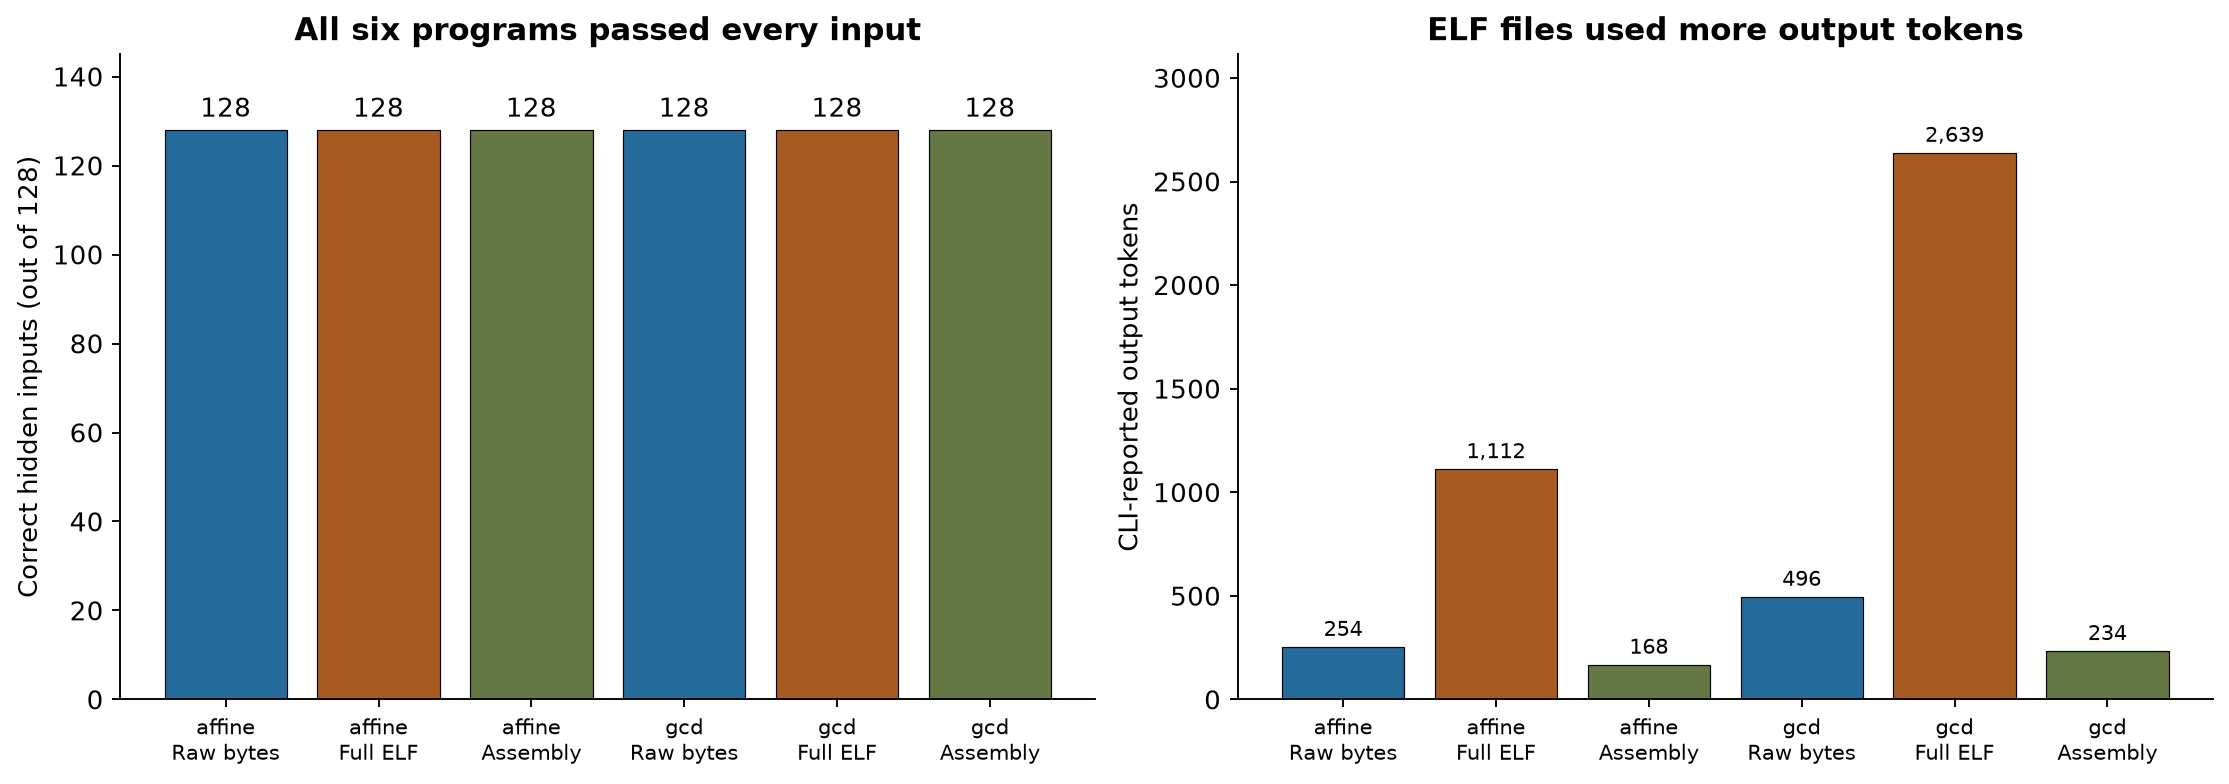

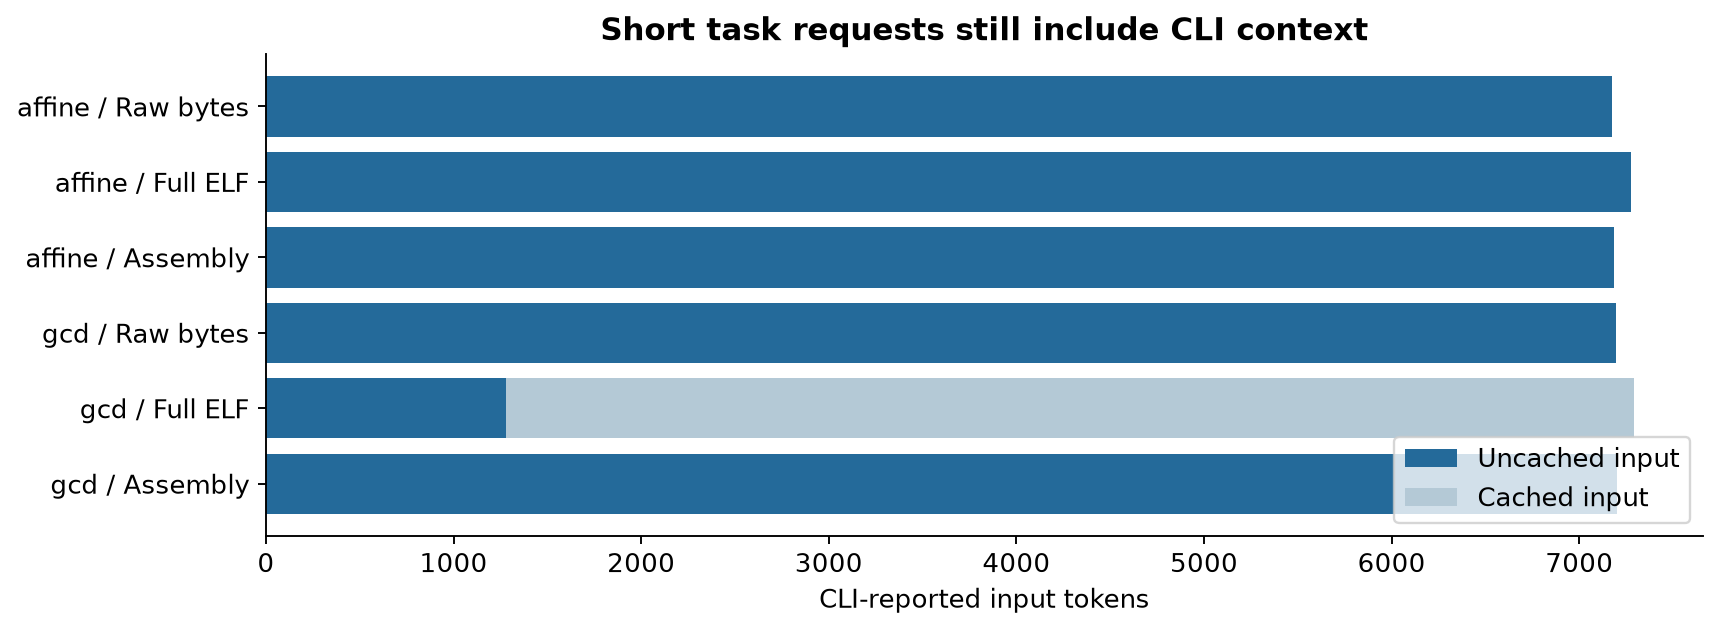

{
  "input_tokens": 43327,
  "cached_input_tokens": 6016,
  "output_tokens": 4903,
  "reasoning_output_tokens": 4311,
  "artifact_output_tokens": 592,
  "correct_inputs": 768,
  "observed_tool_calls": 0,
  "programs_passed": 6,
  "calls": 6,
  "api_equivalent_usd": 0.12425359999999999,
  "generation_seconds": 122.67841200000001,
  "actual_invoice_usd": null,
  "pricing_source": "https://developers.openai.com/api/docs/models/gpt-6.1-sol",
  "separate_reasoning_tokens_available": true
}
Fresh spend on replay: US$0. Recorded standard API equivalent: US$0.124254. Actual subscription charge unavailable.


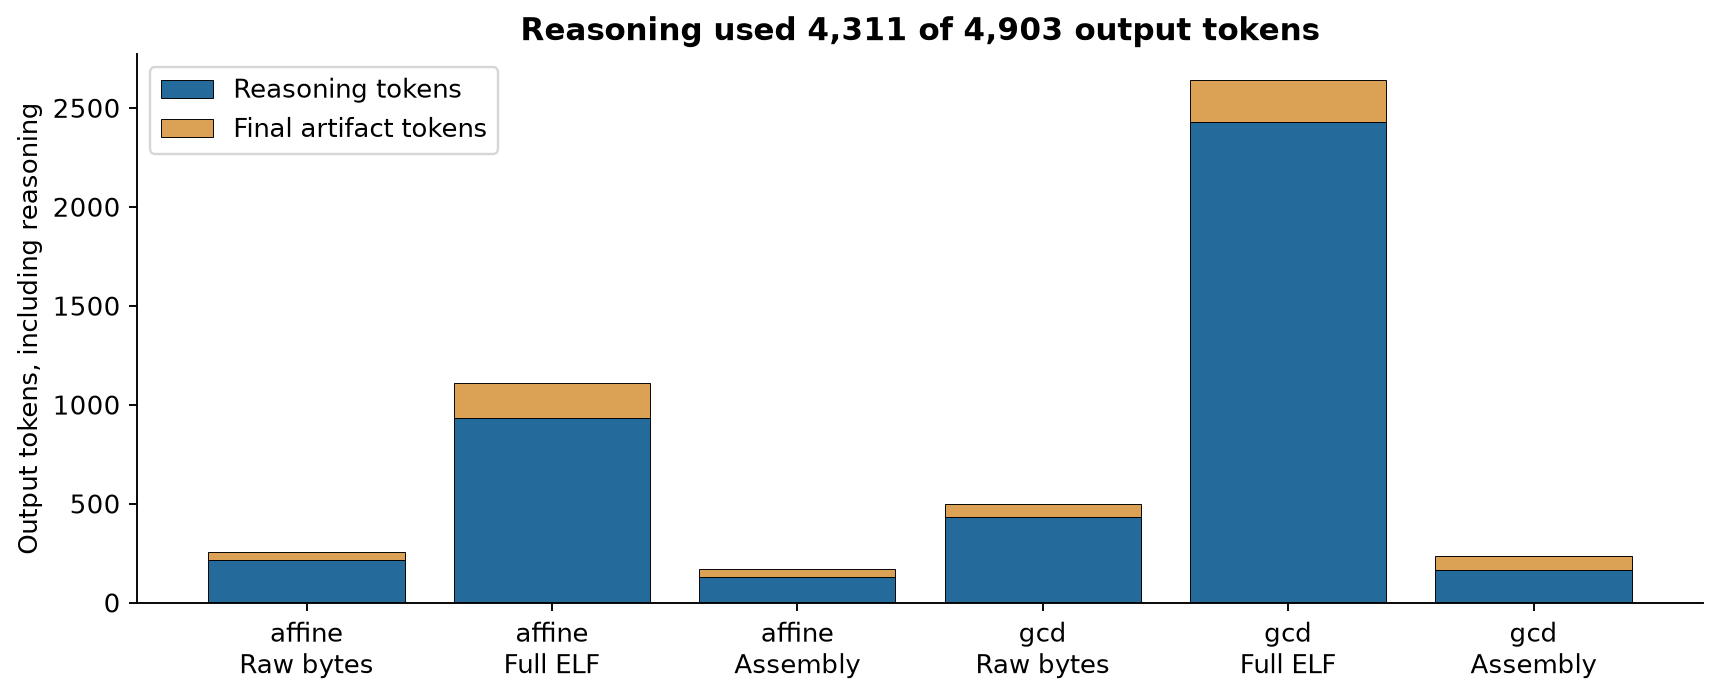

In [5]:
labels = [r['task'] + '\n' + {'raw_hex':'Raw bytes', 'elf_hex':'Full ELF', 'assembly':'Assembly'}[r['format']] for r in RESULTS.to_dict('records')]
colors = [{'raw_hex':'#246a9a', 'elf_hex':'#a85b20', 'assembly':'#667746'}[f] for f in RESULTS['format']]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout='constrained')
x = np.arange(len(RESULTS))
axes[0].tick_params(axis='x', labelsize=9)
axes[1].tick_params(axis='x', labelsize=9)
axes[0].bar(x, RESULTS['correct_inputs'], color=colors, edgecolor='black', linewidth=0.5)
axes[0].set(xticks=x, xticklabels=labels, ylabel='Correct hidden inputs (out of 128)', ylim=(0, 145),
            title="All six programs passed every input")
for i, v in enumerate(RESULTS['correct_inputs']): axes[0].text(i, v+3, str(v), ha='center')
axes[1].bar(x, RESULTS['output_tokens'], color=colors, edgecolor='black', linewidth=0.5)
axes[1].set(xticks=x, xticklabels=labels, ylabel='CLI-reported output tokens', title='ELF files used more output tokens' if RESULTS.query("format == 'elf_hex'")['output_tokens'].mean() > RESULTS.query("format != 'elf_hex'")['output_tokens'].mean() else 'Output usage varies across the six artifacts')
for i, v in enumerate(RESULTS['output_tokens']): axes[1].text(i, v+max(RESULTS['output_tokens'])*0.02, f'{v:,}', ha='center', fontsize=9)
axes[1].set_ylim(0, max(RESULTS['output_tokens'])*1.18)
fig.savefig(FIGURES / 'pilot_results.png', bbox_inches='tight')
display(Image(filename=str(FIGURES / 'pilot_results.png')))
plt.close(fig)

fig, ax = plt.subplots(figsize=(10, 3.6), layout='constrained')
ax.barh(x, RESULTS['input_tokens'] - RESULTS['cached_input_tokens'], color='#246a9a', label='Uncached input')
ax.barh(x, RESULTS['cached_input_tokens'], left=RESULTS['input_tokens']-RESULTS['cached_input_tokens'], color='#b4c9d6', label='Cached input')
ax.set(yticks=x, yticklabels=[s.replace('\n',' / ') for s in labels], xlabel='CLI-reported input tokens',
       title='Short task requests still include CLI context')
ax.invert_yaxis(); ax.legend(loc='lower right')
fig.savefig(FIGURES / 'input_usage.png', bbox_inches='tight')
display(Image(filename=str(FIGURES / 'input_usage.png')))
plt.close(fig)

totals = {k: int(RESULTS[k].sum()) for k in ['input_tokens', 'cached_input_tokens', 'output_tokens', 'reasoning_output_tokens', 'artifact_output_tokens', 'correct_inputs', 'observed_tool_calls']}
totals.update({'programs_passed': int(RESULTS['program_pass'].sum()), 'calls': len(RESULTS),
               'api_equivalent_usd': float(RESULTS['api_equivalent_usd'].sum()),
               'generation_seconds': float(RESULTS['seconds'].sum()), 'actual_invoice_usd': None,
               'pricing_source': 'https://developers.openai.com/api/docs/models/gpt-6.1-sol',
               'separate_reasoning_tokens_available': any('reasoning' in str(r['usage']).lower() for r in CACHE_ROWS)})
save(DATA / 'usage_summary.json', totals)
print(json.dumps(totals, indent=2))
print('Fresh spend on replay: US$0. Recorded standard API equivalent: US$' + format(totals['api_equivalent_usd'], '.6f') + '. Actual subscription charge unavailable.')

fig, ax = plt.subplots(figsize=(10, 4), layout='constrained')
ax.bar(x, RESULTS['reasoning_output_tokens'], color='#246a9a', edgecolor='black', linewidth=0.4, label='Reasoning tokens')
ax.bar(x, RESULTS['artifact_output_tokens'], bottom=RESULTS['reasoning_output_tokens'], color='#dba256', edgecolor='black', linewidth=0.4, label='Final artifact tokens')
ax.set(xticks=x, xticklabels=labels, ylabel='Output tokens, including reasoning',
       title=f"Reasoning used {totals['reasoning_output_tokens']:,} of {totals['output_tokens']:,} output tokens")
ax.legend()
fig.savefig(FIGURES / 'reasoning_usage.png', bbox_inches='tight')
display(Image(filename=str(FIGURES / 'reasoning_usage.png')))
plt.close(fig)


<a id="6-token-usage-and-cost"></a>

## 6. Token usage and cost

The original reason to keep the study this small was uncertainty about how much work direct encoding would require. The useful distinction is between the final artifact and the computation used to produce it. The CLI reports total output tokens and a reasoning subset. Subtracting that subset gives the final-artifact token count; adding it to total output again would double-count reasoning.

Before reading the chart, compare the total height with the smaller final-artifact segment. Each bar is one call, with output tokens on the vertical axis. Blue counts reported reasoning and gold counts the remaining output. These are usage records, not a transcript of hidden reasoning or a timing profile of the generated program.

![Reasoning accounts for 4,311 of the pilot's 4,903 output tokens; full ELF GCD is the largest call at 2,639 tokens.](figures/reasoning_usage.png)

Reasoning accounts for 4,311 of 4,903 output tokens, or 87.9%. The final artifacts account for 592. The complete GCD file uses the most output: 2,639 tokens, including 2,430 reasoning tokens and 209 artifact tokens. The arithmetic assembly control uses the least: 168 total output tokens. These observed values replace the unmeasured assumption that a small request would necessarily need several thousand reasoning tokens.

| Task | Format | Input tokens | Cached input | Output tokens | Reasoning subset | Final artifact tokens | Seconds | API equivalent, USD |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| affine | Raw bytes | 7,177 | 0 | 254 | 217 | 37 | 9.3 | 0.016894 |
| affine | Complete ELF | 7,277 | 0 | 1,112 | 935 | 177 | 26.1 | 0.025674 |
| affine | Assembly control | 7,184 | 0 | 168 | 128 | 40 | 8.7 | 0.016048 |
| gcd | Raw bytes | 7,194 | 0 | 496 | 435 | 61 | 14.4 | 0.019348 |
| gcd | Complete ELF | 7,294 | 6,016 | 2,639 | 2,430 | 209 | 56.3 | 0.029548 |
| gcd | Assembly control | 7,201 | 0 | 234 | 166 | 68 | 7.8 | 0.016742 |

The six calls together used 43,327 input tokens, including 6,016 cached tokens, and 4,903 output tokens. Total generation wall time, summed across sequential calls, was 122.7 seconds. It includes service and CLI overhead; it is not the execution time of the generated binaries. There was one cache-reading request and no input cache-write tokens reported. The observations come from one request per slot, so neither a typical latency nor a stable token distribution can be estimated from them.

The two complete-file requests together use 3,751 output tokens. The two raw functions use 750, and the two assembly controls use 402. In this sample, producing the complete file is the largest generation burden. That comparison bundles the ELF headers, file input/output and direct byte encoding, while the assembly conditions return functions. It cannot identify how much of the difference comes from any one of those additions or predict how that difference scales with file size.

The input chart separates uncached and cached input for the same six calls. The horizontal axis counts tokens reported by the CLI, not the number of characters in the visible user prompt. A light segment shows the cached portion of the complete GCD request. No claim about why that single cache hit occurred is needed to compute its price.

![Each call reports about 7,200 input tokens; 6,016 cached tokens occur in the complete GCD request.](figures/input_usage.png)

Input usage runs from 7,177 to 7,294 tokens per call even though each task request is short. The no-generation preflight reports mandatory runtime context beyond the supplied task text. This supports treating CLI input overhead as part of a cost forecast, rather than estimating from the visible specification alone. The preflight counts characters by context block, not tokens, so it does not provide an exact token allocation to each source of that overhead.

At the documented standard rates of US$2 per million uncached input tokens, US$0.10 per million cached input tokens and US$10 per million output tokens, the calculation is `(37,311*2 + 6,016*0.10 + 4,903*10) / 1,000,000 = US$0.1242536`. Without the observed input cache read, the same counts would give US$0.135684. The rounded headline is about 12 US cents, and the saved unrounded figures remain in the results. [Published rates](https://developers.openai.com/api/docs/models/gpt-6.1-sol).

These are standard API equivalents for calls made through the CLI. No API billing route was used to generate the answers. The actual subscription invoice or quota conversion is not exposed, so a measured cash charge is unknown. A cached notebook replay makes zero fresh model calls and has zero additional model spend. Local compute time and electricity were not priced.

<a id="7-error-analysis-and-boundary-cases"></a>

## 7. Error analysis and boundary cases

No model failure or disagreement occurred on the frozen test set. An error section cannot manufacture one to illustrate a category. Instead, the cases below show boundaries a plausible but incorrect implementation could have missed, together with what all three saved artifacts actually returned. The ordinary case in section 4 and these boundary cases supply measured examples with stable IDs. They were selected for their mathematical role from the explicit boundary group; the complete per-input table remains available so these examples do not substitute for aggregate coverage.

### Overflow in the affine calculation

Item `affine-008` has both inputs equal to the largest unsigned 64-bit value, 18,446,744,073,709,551,615. Before reducing to 64 bits, multiplying by 37 and 11 adds up to 48 times that value, then adds 23. Since `48*(2^64-1)+23 = 48*2^64-25`, the requested wrapped answer is `2^64-25`, or 18,446,744,073,709,551,591.

| Case | Expected | Raw bytes observed | Complete ELF observed | Assembly control observed |
|---|---:|---:|---:|---:|
| `affine-008` | 18,446,744,073,709,551,591 | 18,446,744,073,709,551,591 | 18,446,744,073,709,551,591 | 18,446,744,073,709,551,591 |

All three return the required wrapped integer. An implementation that uses only 32-bit intermediate arithmetic could still pass the small request example but fail this case. The observed raw instructions use 64-bit destinations and keep the low 64 bits, which is consistent with the requested wrap. The example supports that particular implementation boundary; the full 128 cases provide broader numerical checks without proving equivalence for all possible pairs.

### A GCD loop with more than one remainder

Item `gcd-005` uses 48 and 18. Replacing a pair with the second number and the remainder leaves its common divisors unchanged: `(48,18)` becomes `(18,12)`, then `(12,6)`, then `(6,0)`. When the second number reaches zero, the first number is the answer, 6.

| Case | Expected | Raw bytes observed | Complete ELF observed | Assembly control observed |
|---|---:|---:|---:|---:|
| `gcd-005` | 6 | 6 | 6 | 6 |

The raw answer contains a conditional jump around the loop for an initial zero and a backward conditional jump after each remainder. Its instruction bytes decode to unsigned division, followed by moving the divisor and remainder into the next pair. A wrong jump displacement could send execution into another instruction or a data region, even if every instruction encoding looked individually familiar. Actual execution succeeds for this case and all 127 other GCD pairs in each format, which tests the assembled branch layout as well as the chosen algorithm.

### Both inputs zero

Item `gcd-000` uses `(0,0)` and has a stipulated answer of zero. The usual remainder operation must not divide by zero. The raw artifact first moves the initial values into working registers, tests the second value, and branches straight to its return when that value is zero.

| Case | Expected | Raw bytes observed | Complete ELF observed | Assembly control observed |
|---|---:|---:|---:|---:|
| `gcd-000` | 0 | 0 | 0 | 0 |

All three produce zero without an execution error. This illustrates why successful numeric output and successful execution are recorded separately. A division exception would fail the program even if a loose scorer happened to fill in a default numeric value of zero. The evaluator never converts an exception or missing output into a correct integer.

### A full-width value returned unchanged

Item `gcd-015` uses the largest unsigned 64-bit value as its first input and zero as its second. Its expected answer is that same largest value. A function that truncates the return to 32 bits or treats it as a negative signed integer would violate the specified result.

| Case | Expected | Raw bytes observed | Complete ELF observed | Assembly control observed |
|---|---:|---:|---:|---:|
| `gcd-015` | 18,446,744,073,709,551,615 | 18,446,744,073,709,551,615 | 18,446,744,073,709,551,615 | 18,446,744,073,709,551,615 |

The complete executable writes eight `ff` bytes for this input, which the evaluator reads as the requested unsigned value. The raw function returns the same bit pattern in its 64-bit return register. This joins the arithmetic contract to the file interface: checking a printed decimal string alone would have tested a different output format from the one requested.

### Opposite sides of the signed boundary

Item `gcd-010` uses 9,223,372,036,854,775,807 and 9,223,372,036,854,775,809. Both numbers are odd and differ by two, so their greatest common divisor is one. The upper input exceeds the largest positive signed 64-bit number. The raw bytes use unsigned division, as the task requires.

| Case | Expected | Raw bytes observed | Complete ELF observed | Assembly control observed |
|---|---:|---:|---:|---:|
| `gcd-010` | 1 | 1 | 1 | 1 |

This case passes in all formats. It was present in the 16-case boundary group before collection, rather than added after noticing which instructions the model chose. It is evidence for full-width handling within the specified domain. It does not test negative numbers, whose meaning is deliberately outside that domain.

The useful missing failure is therefore itself a limitation: these tasks are too easy to expose the boundaries of direct byte generation. There is no basis for claiming that format errors are rare in general. The next experiment should add tasks with more branches, address calculations and data layouts before treating a six-of-six result as a dependable workflow.

<a id="8-what-this-result-supports"></a>

## 8. What this result supports

The complete ELF artifacts establish that a model can already emit bytes that Linux loads and runs correctly for these two tasks. The raw functions separately establish working processor instruction encodings under a supplied interface. The successful control shows that the same model can also express the algorithms in assembly. Those are concrete capability observations, and the saved bytes make them inspectable without relying on an answer that merely claims to be executable.

The result does not test production software. A 192-byte arithmetic program or a 224-byte number-theory program has no graphical interface, authentication system, dependency graph, persistent database or cross-platform build. There are no variable-length structures, heap allocations, floating-point operations or multi-threaded interactions. These omitted requirements are reasons to enlarge the task design, not evidence that the model would either pass or fail them.

The study is an existence test rather than a reliability estimate. There are two chosen algorithms and one attempt per format. Running 128 inputs checks an individual program more thoroughly, but does not create 128 independent opportunities for the model to generate a new program. Repeated fresh generations are needed to measure how often a method succeeds. There is no statistically defensible way to extrapolate this task set into a general binary-writing success percentage.

The direct-format prompts provide architecture, interface, syscall numbers and practical file-format guidance. That is an intentional definition of the task. They contain no reference implementation, header hex template or hidden answers. The experiment therefore asks whether a model can implement a precisely stated small program, not whether it can discover a processor or file format unaided. It also cannot determine whether the model internally pictured assembly or higher-level code before returning bytes; only external tool use and returned artifacts are observed.

Generation was fixed before the answers arrived, and no model was asked to repair an output. Replay added checks for preserved registers and trusted native-loader controls after the initial successful scores were visible; these checks use exactly the same cached responses and leave all six program scores unchanged. The original parser and the numerical task definitions did not change. The dated record and exact scope are in [PROTOCOL.md](data/PROTOCOL.md).

There is also no compiler performance finding. The control is an assembler, which translates chosen instructions. No optimising compiler is given an equivalent high-level source program, and the study does not benchmark native execution speed, memory use or instruction throughput. The slightly shorter assembly GCD function does not establish superiority of either generation path. Claims that AI-generated binaries are more efficient than compiler output remain untested here.

Token usage is useful for planning more pilots of similar size, with the same CLI and effort setting. It is not a per-byte pricing law. The smallest and largest calls differ in task and interface, their inputs include CLI context, and provider caching appears in only one slot. A bigger program could require much more reasoning or fail before it emits any useful bytes. Any larger budget should be based on measured samples at its own complexity level.

For someone deciding what to try next, this evidence supports keeping direct executable generation as a testable approach for small, precisely specified programs. The uncertainty now concerns the point where reliable encoding, file layout and program logic stop fitting into one correct first attempt. More elaborate tasks and repeated generations can locate that boundary; this ceiling cannot.

<a id="9-reproduction-and-saved-evidence"></a>

## 9. Reproduction and saved evidence

Open [the executed notebook](43_direct_binary_pilot.ipynb) to see the complete narrative, exact requests, saved outputs, scorer and chart code. The notebook imports no code from another repository file. All helpers, including the native-runner source, model-call wrapper, parser, emulator and trace helper, are defined in its cells. A normal replay loads the six cached responses, reruns execution checks and redraws figures without any model calls.

Install [requirements.txt](requirements.txt), and have a local Linux Docker engine with the recorded amd64 Python image available. The immutable local image ID is recorded in the notebook and protocol. If that exact image is unavailable on another computer, explicitly record the replacement image and platform before replaying; the original native environment is not promised by a moving image tag. CPU emulation does not require Docker, but complete executable verification does.

```powershell
cd notebooks/43-direct-binary-pilot
python -m pip install -r requirements.txt
python -m nbconvert --to notebook --execute --inplace 43_direct_binary_pilot.ipynb
```

Fresh generation is disabled by default. The size knobs at the top are `N_TASKS`, `MODELS`, `FORMATS` and `MAX_NEW_CALLS`. Setting `DIRECT_BINARY_FRESH=1` explicitly permits missing-cache requests, still capped at six new calls. An existing cache is always loaded rather than overwritten. Changing a prompt or model requires updating the frozen-request record and protocol for a distinct run; replay checks request identity. There is no automatic retry or expansion after a failure.

The primary saved files are [results.csv](data/results.csv), [results.json](data/results.json), [case_results.json](data/case_results.json), [artifacts.json](data/artifacts.json), [tasks.json](data/tasks.json), [requests.json](data/requests.json), [usage_summary.json](data/usage_summary.json) and [preflight.json](data/preflight.json). Individual cache filenames are the full-request hashes and contain request text, command settings, raw CLI events, final response, timing and the provider usage fields. Hex artifacts are also saved separately under `data/artifacts/`. None of those files contains API credentials.

Each fresh request was sent to the local Langfuse instance after the response was cached; all six trace submissions returned HTTP 200. Replay sends no new traces. The original trace helper recorded inclusive output usage as one total; the final helper separates the reported reasoning subset for future calls. The immutable raw cache is the accounting source for the split reported here. A dry-run inspection of the repository backfill path was performed without resending existing pilot traces.

The run contains six completed requests, zero blocked or timed-out requests, zero observed tool calls and zero repair requests. It used 43,327 input tokens, 6,016 of them cached, and 4,903 output tokens. The recorded standard API equivalent is US$0.1242536. Actual subscription charges are unknown. The notebook prints spend at the end and makes fresh replay spend explicit.

<a id="10-future-work-and-further-reading"></a>

## 10. Future work and further reading

The documentation links below were opened and checked on November 3, 2026 (America/Toronto). Sources identify the interfaces and tools; all measured program, byte and usage claims come from this pilot's saved artifacts.

### Future work

- Add a planned complexity ladder: array sums, variable-length text parsing, a small checksum and a stateful parser. Keep the same input contract within each format and measure first-attempt program passes, parse failures and execution failures. The six-of-six ceiling motivates seeking the first complexity level that separates the methods.
- Repeat each task-format pair at least ten times with fresh sessions and fixed settings. Measure the distribution of output tokens, launch success and full-input correctness. One candidate per slot cannot tell whether the observed success or the low output usage is repeatable.
- Add a high-level source condition compiled with a pinned optimising compiler, with an identical program interface and equivalent validation. Only then measure code size and native runtime. The present assembler control and unequal function/file interfaces leave the compiler-efficiency claim unanswered.
- Add an explicitly bounded repair condition that receives one execution diagnostic, alongside untouched first attempts. Measure extra tokens and recovered programs. This pilot used no feedback and observed no failures, so repair value requires harder cases where failures actually occur.
- Run the same specifications on a second processor architecture and at a second reasoning effort. Measure correct encoding, platform-specific failures and usage. The present evidence concerns only x86-64 and one high-effort model configuration.

### Further reading

- [ELF header](https://gabi.xinuos.com/elf/02-eheader.html) (Xinuos, ELF Object File Format 4.3 draft, accessed 2026). Describes the file identification and entry-point fields the complete executable must supply.
- [Program loading](https://gabi.xinuos.com/elf/07-pheader.html) (Xinuos, ELF Object File Format 4.3 draft, accessed 2026). Explains how segment records tell the loader which bytes become a process image.
- [x86-64 psABI project](https://gitlab.com/x86-psABIs/x86-64-ABI) (x86 psABIs contributors, accessed 2026). Maintains the calling-convention specification behind the function interface used here.
- [Unicorn programming tutorial](https://www.unicorn-engine.org/docs/tutorial.html) (Unicorn contributors, accessed 2026). Shows how raw instruction bytes can be mapped and executed independently of a native executable file.
- [Linux x86-64 syscall table](https://github.com/torvalds/linux/blob/master/arch/x86/entry/syscalls/syscall_64.tbl) (Linux contributors, accessed 2026). Gives the operating-system call identifiers used for the complete files' input, output and exit.

In [6]:
print('Fresh model calls in this replay: 0' if not ALLOW_FRESH else 'Fresh calls permitted; cached slots reused.')
print('Recorded standard API equivalent: US$' + format(totals['api_equivalent_usd'], '.6f'))
print('Actual subscription invoice: unavailable.')

Fresh model calls in this replay: 0
Recorded standard API equivalent: US$0.124254
Actual subscription invoice: unavailable.
